
# 2.3 Modelo No Supervisado: Clusterización con K-Means

**Objetivo:** Identificar segmentos de sesiones de navegación con características similares mediante el algoritmo K-Means.

Se utilizarán variables relacionadas con la cantidad de páginas visitadas, el tiempo dedicado a cada sección y las tasas de rebote y salida.

El análisis permitirá identificar diferentes patrones de navegación y posteriormente relacionar los clústeres obtenidos con la realización de compras.

**Justificación del modelo:**

Se eligió K-Means porque queremos agrupar sesiones que tengan comportamientos de navegación similares, sin utilizar previamente las etiquetas de compra.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from google.colab import drive
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

Carga del conjunto de datos

In [3]:
# Conectar Google Drive
drive.mount('/content/drive')

# Cargar el dataset preparado
ruta = '/content/drive/MyDrive/mineriaDatos/online_shoppers_sin_duplicados.csv'

df = pd.read_csv(ruta)

print("Dimensiones del dataset:", df.shape)

display(df.head())

Mounted at /content/drive
Dimensiones del dataset: (12205, 23)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,Revenue,PaginasTotales,VisitoInformativas,TiempoPromedioProducto,PorcentajePaginasProducto,TiempoPromedioPagina
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,Returning_Visitor,False,False,1,0,0.000000,1.0,0.000000
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,2,Returning_Visitor,False,False,2,0,32.000000,1.0,32.000000
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,9,3,Returning_Visitor,False,False,1,0,0.000000,1.0,0.000000
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,4,Returning_Visitor,False,False,2,0,1.333333,1.0,1.333333
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,4,Returning_Visitor,True,False,10,0,62.750000,1.0,62.750000



**Observaciones:**

Se cargó el dataset preparado, que contiene 12,205 sesiones y 23 variables. Para K-Means utilizaremos 8 características relacionadas con la navegación.



## Selección de variables para K-Means

Se seleccionaron 8 variables numéricas que describen el comportamiento de navegación de las sesiones.

No se incluirá `Revenue` en el entrenamiento, debido a que K-Means es un algoritmo no supervisado y busca encontrar grupos sin conocer previamente si una sesión terminó en compra.


In [4]:
# Seleccionar las variables numéricas para K-Means
columnas_kmeans = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates'
]

X = df[columnas_kmeans].copy()

print("Dimensiones de los datos:", X.shape)

display(X.describe().T)

Dimensiones de los datos: (12205, 8)


,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.00000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.75000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.00000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.37500
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.00000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.52223
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.20000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.20000



**Observaciones:**

- Se seleccionaron 8 características numéricas relacionadas con la cantidad de páginas visitadas, el tiempo de navegación y las tasas de rebote y salida.
- Las variables seleccionadas permiten analizar diferentes comportamientos de los visitantes dentro del sitio web.
- Se excluyó `Revenue` para que los clústeres se formen únicamente a partir de la similitud entre las sesiones.
- Las estadísticas descriptivas permiten observar las diferencias de escala entre las características, por lo que será necesario estandarizarlas antes de aplicar K-Means.



## Normalización de escala: estandarización de variables

Se utilizará `StandardScaler` para estandarizar las 8 características seleccionadas.

Como K-Means utiliza distancias euclidianas para agrupar las observaciones, es importante que las variables tengan escalas comparables y evitar que las de mayor magnitud dominen el cálculo de las distancias.


In [5]:
# Estandarizar las variables
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Dimensiones después de estandarizar:", X_scaled.shape)

display(X_scaled.head())

# Comprobar la estandarización
display(pd.DataFrame({
    'Media': X_scaled.mean(),
    'Desviación estándar': X_scaled.std(ddof=0)
}).round(3))

Dimensiones después de estandarizar: (12205, 8)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
0,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394
1,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.595451,-0.450137,1.268054
2,-0.702302,-0.460019,-0.398824,-0.246257,-0.696218,-0.628793,3.969402,3.434394
3,-0.702302,-0.460019,-0.398824,-0.246257,-0.673793,-0.627404,0.654748,2.134590
4,-0.702302,-0.460019,-0.398824,-0.246257,-0.494387,-0.301889,-0.008183,0.184884


,Media,Desviación estándar
Administrative,-0.0,1.0
Administrative_Duration,-0.0,1.0
Informational,0.0,1.0
Informational_Duration,-0.0,1.0
ProductRelated,-0.0,1.0
ProductRelated_Duration,0.0,1.0
BounceRates,-0.0,1.0
ExitRates,-0.0,1.0



**Observaciones:**

Después de aplicar `StandardScaler`, las 8 variables tienen una media cercana a 0 y una desviación estándar de 1.

Con esto evitamos que las variables con valores más grandes tengan mayor influencia en las distancias utilizadas por K-Means. No se eliminaron registros ni valores atípicos.


In [15]:
# Validar los datos preparados para K-Means
print("Dimensiones:", X_scaled.shape)
print("Valores faltantes:", X_scaled.isna().sum().sum())
print("Valores infinitos:", np.isinf(X_scaled.to_numpy()).sum())

assert X_scaled.shape == (12205, 8)
assert X_scaled.isna().sum().sum() == 0
assert np.isfinite(X_scaled.to_numpy()).all()

Dimensiones: (12205, 8)
Valores faltantes: 0
Valores infinitos: 0



## Aplicación inicial de K-Means

Se aplicará inicialmente K-Means con 3 clústeres para observar cómo se agrupan las sesiones según sus características de navegación.

Este primer modelo es exploratorio. Posteriormente se utilizarán el método del codo y el coeficiente de silueta para determinar un número adecuado de clústeres.


In [19]:
# Primer K-Means con K = 3
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)

df_km1 = df.copy()
df_km1["Cluster"] = kmeans.fit_predict(X_scaled)

print("Sesiones por clúster:")
display(df_km1["Cluster"].value_counts().sort_index())

Sesiones por clúster:


,count
Cluster,
0,1607
1,9679
2,919



**Observaciones:**

Al probar K-Means con **K = 3**, obtuvimos la siguiente distribución:

- Clúster 0: 1,607 sesiones (13.17 %).
- Clúster 1: 9,679 sesiones (79.30 %).
- Clúster 2: 919 sesiones (7.53 %).

El clúster 1 concentra casi el 80 % de las sesiones. Los grupos tienen tamaños muy diferentes, pero esto no representa necesariamente un error.

Por ahora K = 3 es una prueba inicial; falta comprobar si es adecuado mediante el método del codo y la silueta.


### Comparación de las variables por clúster

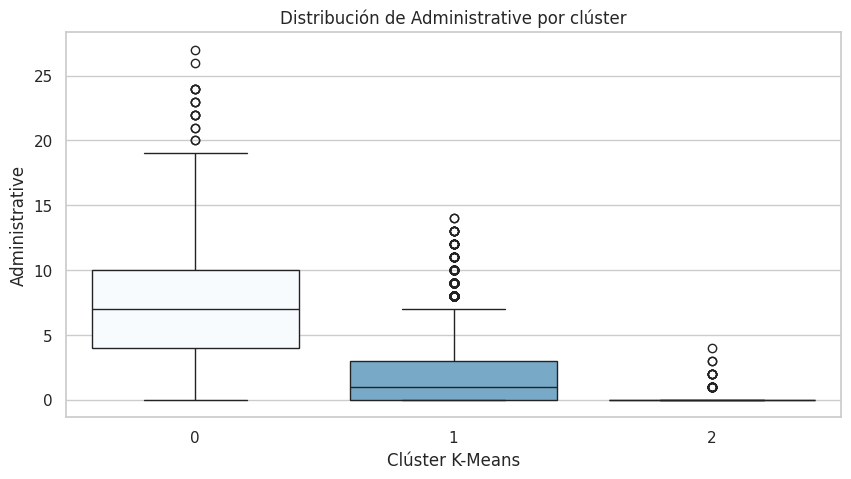

--------------------------------------------------


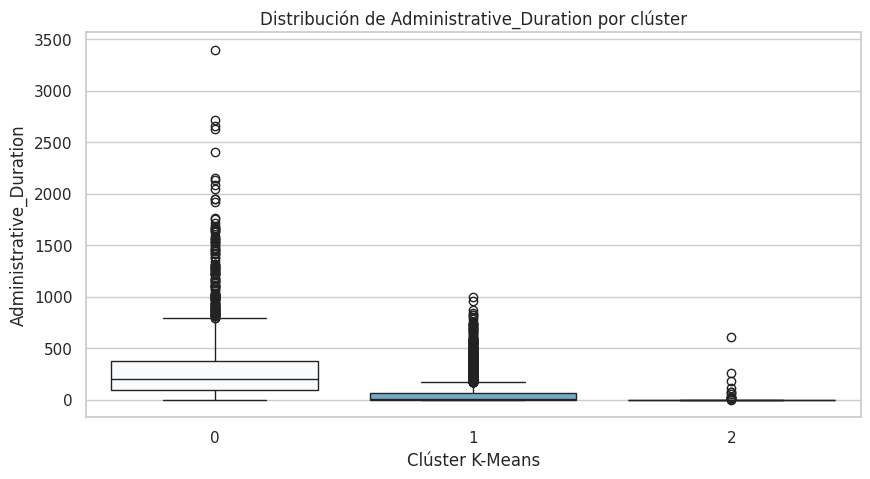

--------------------------------------------------


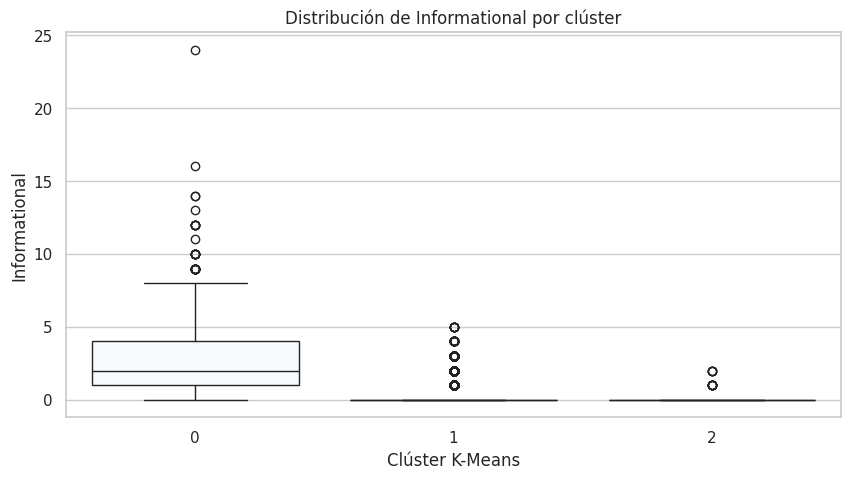

--------------------------------------------------


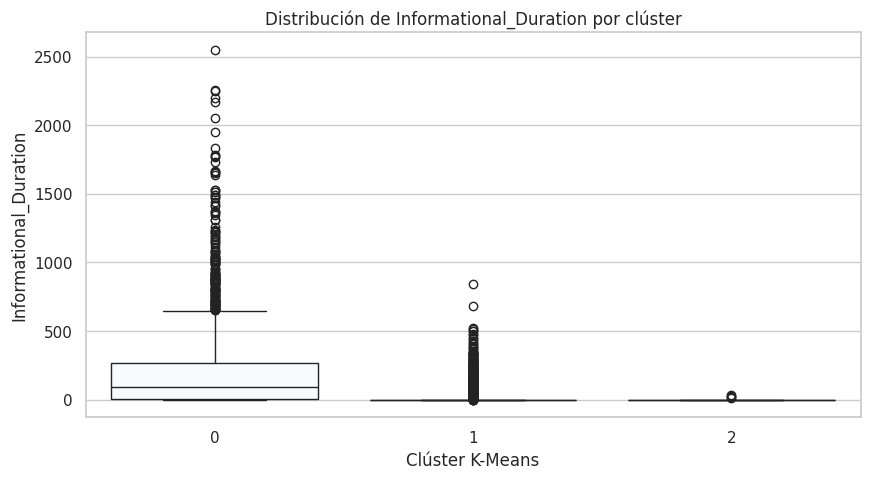

--------------------------------------------------


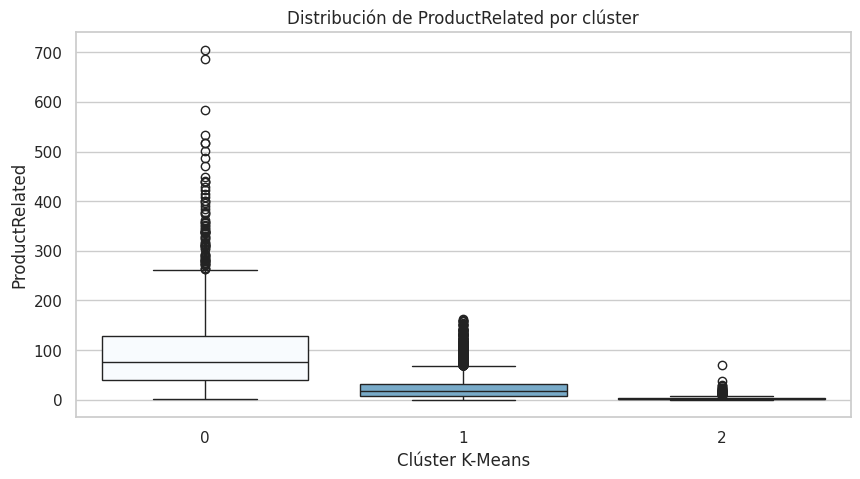

--------------------------------------------------


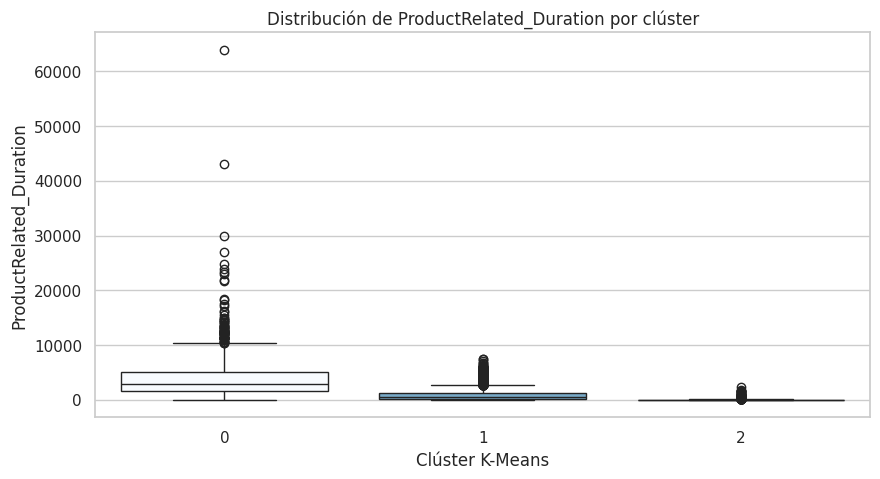

--------------------------------------------------


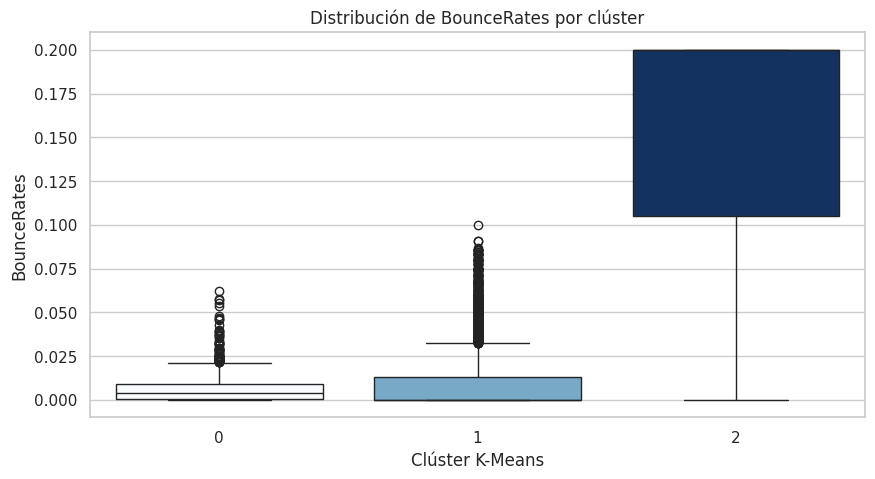

--------------------------------------------------


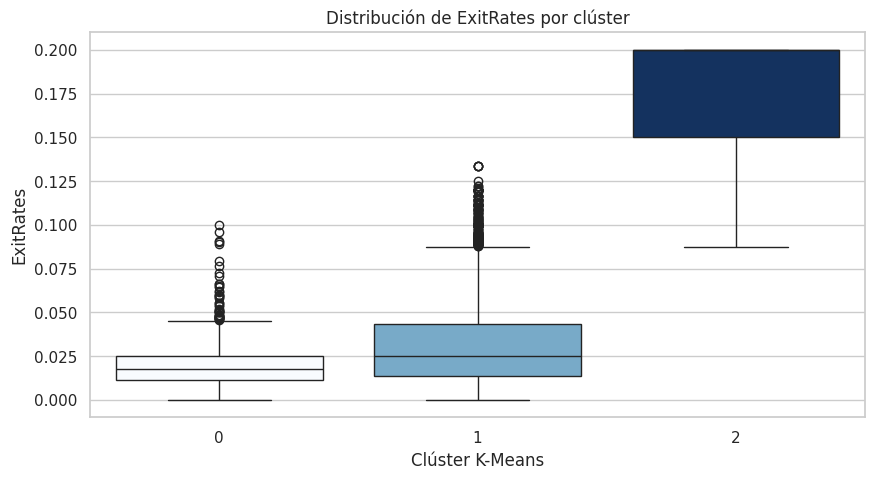

--------------------------------------------------


In [8]:

# Comparar las variables de navegación entre clústeres
for v in columnas_kmeans:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df_km1,
        x="Cluster",
        y=v,
        hue="Cluster",
        palette="Blues",
        legend=False
    )

    plt.title(f"Distribución de {v} por clúster")
    plt.xlabel("Clúster K-Means")
    plt.ylabel(v)
    plt.show()
    print("-" * 50)


**Observaciones**

- **Clúster 0 — Navegación intensiva:** Presenta las mayores medianas y una mayor dispersión en la cantidad de páginas administrativas, informativas y de productos, así como en los tiempos de navegación. También registra numerosos valores atípicos, especialmente en `ProductRelated` y `ProductRelated_Duration`. Sus tasas de rebote y salida son bajas.

- **Clúster 1 — Navegación moderada:** Presenta valores intermedios de páginas visitadas y tiempos de navegación, con una dispersión menor que el clúster 0. Aunque existen valores atípicos, la mayoría de las sesiones muestra una actividad moderada y tasas de rebote y salida relativamente bajas.

- **Clúster 2 — Navegación breve y alta salida:** Presenta medianas cercanas a cero en las cantidades de páginas visitadas y los tiempos de navegación. A diferencia de los otros grupos, registra las **mayores tasas de rebote y salida**, con valores frecuentemente próximos a 0.20.


### Elección del número óptimo de clústeres y evaluación de la calidad de la clusterización

Se evaluarán diferentes valores de K mediante el método del codo y el coeficiente de silueta, con el objetivo de identificar una agrupación adecuada para las sesiones de navegación.

,K,WCSS,Silueta
0,2,74492.2416,0.5013
1,3,55888.9953,0.5395
2,4,48124.7730,0.4287
3,5,42273.8665,0.4277
4,6,38483.8714,0.3872
5,7,34729.7761,0.3781
6,8,31875.1232,0.3716


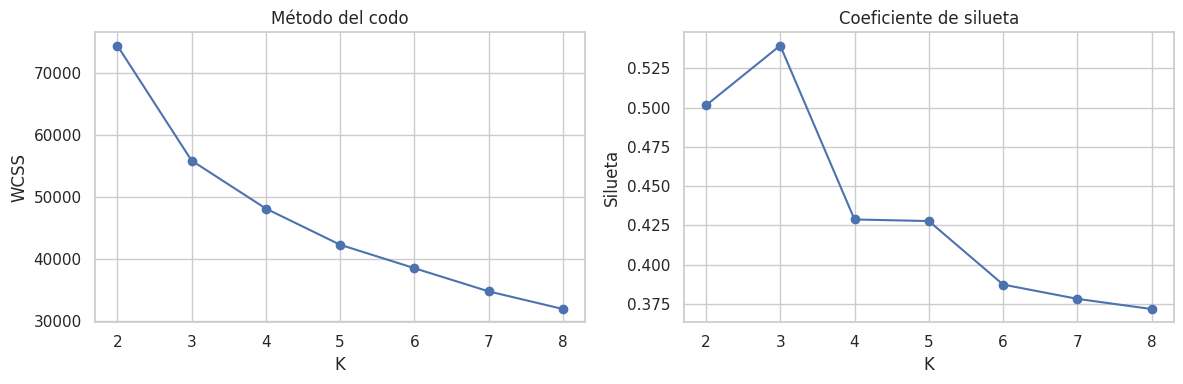

In [23]:
# Comparar diferentes valores de K
resultados = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)

    resultados.append({
        "K": k,
        "WCSS": modelo.inertia_,
        "Silueta": silhouette_score(
            X_scaled, etiquetas,
            sample_size=3000,
            random_state=RANDOM_STATE
        )
    })

resultados_k = pd.DataFrame(resultados)
display(resultados_k.round(4))

# Graficar el codo y la silueta
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(resultados_k["K"], resultados_k["WCSS"], "o-")
axes[0].set(title="Método del codo", xlabel="K", ylabel="WCSS")

axes[1].plot(resultados_k["K"], resultados_k["Silueta"], "o-")
axes[1].set(title="Coeficiente de silueta", xlabel="K", ylabel="Silueta")

plt.tight_layout()
plt.show()


### Evaluación de la calidad de la clusterización

Se compararon diferentes valores de K, desde 2 hasta 8, utilizando el método del codo y el coeficiente de silueta.

- **Método del codo:** La inercia disminuyó de 74,492.24 con K = 2 a 55,889.00 con K = 3. Después de ese punto, las reducciones fueron menos pronunciadas.
- **Coeficiente de silueta:** El valor más alto fue **0.5395 con K = 3**, lo que indica que esta configuración presentó la mejor combinación de cohesión y separación entre los valores evaluados.

La silueta se calculó utilizando una muestra aleatoria de **3,000 sesiones** para reducir el tiempo de procesamiento. K-Means se entrenó con las 12,205 sesiones disponibles.


---


Se seleccionó **K = 3** porque presentó la mayor silueta y el método del codo también mostró una reducción importante de inercia hasta ese punto.


### Modelo definitivo de K-Means

In [10]:

# Modelo definitivo
k_elegido = 3

kmeans = KMeans(
    n_clusters=k_elegido,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans.fit(X_scaled)

# Agregar los clústeres al dataset
df_km = df.copy()
df_km["Cluster"] = kmeans.labels_

display(df_km.head())
display(df_km["Cluster"].value_counts().sort_index())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType,VisitorType,Weekend,Revenue,PaginasTotales,VisitoInformativas,TiempoPromedioProducto,PorcentajePaginasProducto,TiempoPromedioPagina,Cluster
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,Returning_Visitor,False,False,1,0,0.000000,1.0,0.000000,2
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,2,Returning_Visitor,False,False,2,0,32.000000,1.0,32.000000,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,3,Returning_Visitor,False,False,1,0,0.000000,1.0,0.000000,2
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,4,Returning_Visitor,False,False,2,0,1.333333,1.0,1.333333,2
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,4,Returning_Visitor,True,False,10,0,62.750000,1.0,62.750000,1


,count
Cluster,
0,1607
1,9679
2,919


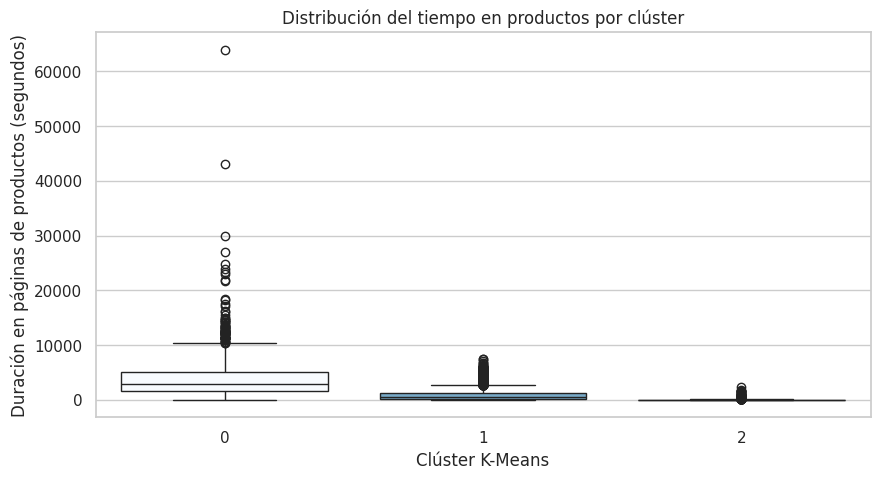

In [11]:

# Comparar el tiempo de navegación en productos entre clústeres
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_km,
    x="Cluster",
    y="ProductRelated_Duration",
    hue="Cluster",
    palette="Blues",
    legend=False
)

plt.title("Distribución del tiempo en productos por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Duración en páginas de productos (segundos)")
plt.show()



**Observaciones de los boxplots:**

El clúster 0 presenta las mayores cantidades de páginas visitadas y tiempos de navegación. También tiene bastantes valores atípicos, especialmente en las variables de duración.

El clúster 1 muestra una actividad intermedia, mientras que el clúster 2 tiene valores cercanos a cero en la mayoría de las variables de navegación.

La principal diferencia del clúster 2 aparece en `BounceRates` y `ExitRates`, donde presenta valores mucho mayores que los otros grupos.

Estas diferencias ayudan a identificar los tres tipos de navegación encontrados por K-Means.



## Análisis de centroides en valores originales

Se obtendrán los centroides de los tres clústeres en las unidades originales de las variables, utilizando `inverse_transform()`.

Esto permitirá identificar las características promedio de las sesiones pertenecientes a cada clúster y comparar sus comportamientos de navegación.


In [12]:

# Visualización de los centroides en valores originales
centroides_originales = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X_scaled.columns
)

centroides_originales.index.name = "Cluster"

display(centroides_originales.round(2))


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
Cluster,,,,,,,,
0,7.39,308.63,2.54,214.98,97.44,3849.36,0.01,0.02
1,1.72,51.59,0.22,8.23,23.93,877.19,0.01,0.03
2,0.05,1.62,0.02,0.10,3.21,63.11,0.16,0.18



## Visualización de los clústeres con PCA

Utilizamos PCA para representar en dos dimensiones los grupos que K-Means formó utilizando 8 variables.

PCA solamente nos ayuda a visualizar las sesiones y los centroides.

Las dos componentes explican aproximadamente el **62.4 % de la variabilidad**, por lo que la gráfica no representa toda la información original.


Varianza explicada: 62.4 %


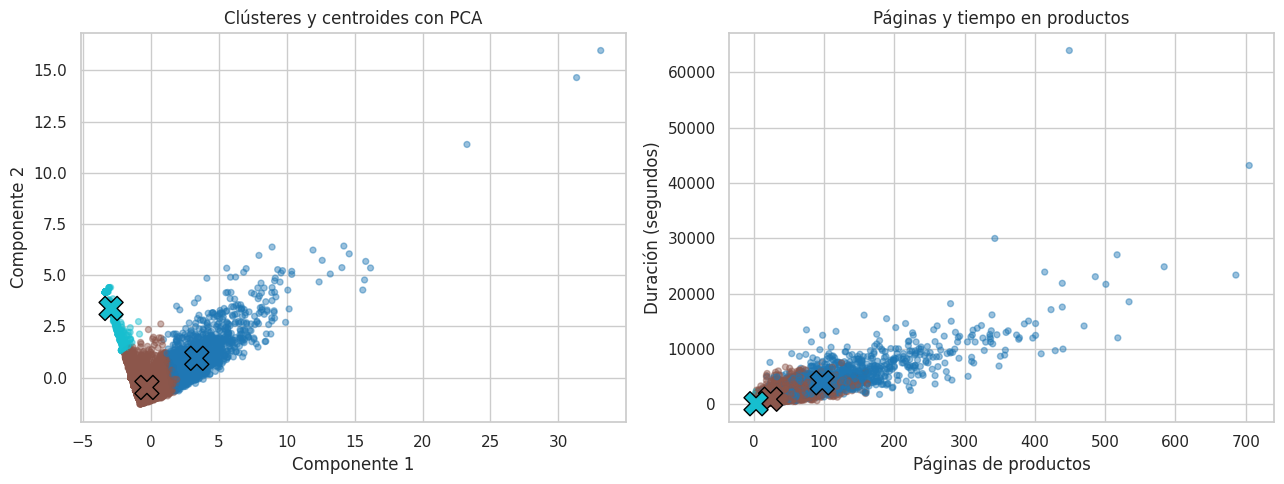

In [22]:
# PCA para visualizar las ocho variables en dos dimensiones
pca = PCA(n_components=2)

datos_pca = pca.fit_transform(X_scaled)
centroides_pca = pca.transform(
    pd.DataFrame(
        kmeans.cluster_centers_,
        columns=X_scaled.columns
    )
)

print("Varianza explicada:", round(
    pca.explained_variance_ratio_.sum() * 100, 2
), "%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfica 1: PCA
axes[0].scatter(
    datos_pca[:, 0], datos_pca[:, 1],
    c=df_km["Cluster"], cmap="tab10", s=18, alpha=0.45
)

axes[0].scatter(
    centroides_pca[:, 0], centroides_pca[:, 1],
    marker="X", c=range(3), cmap="tab10",
    s=300, edgecolor="black"
)

axes[0].set(
    title="Clústeres y centroides con PCA",
    xlabel="Componente 1",
    ylabel="Componente 2"
)

# Gráfica 2: páginas y tiempo en productos
axes[1].scatter(
    df_km["ProductRelated"],
    df_km["ProductRelated_Duration"],
    c=df_km["Cluster"], cmap="tab10", s=18, alpha=0.45
)

axes[1].scatter(
    centroides_originales["ProductRelated"],
    centroides_originales["ProductRelated_Duration"],
    marker="X", c=range(3), cmap="tab10",
    s=300, edgecolor="black"
)

axes[1].set(
    title="Páginas y tiempo en productos",
    xlabel="Páginas de productos",
    ylabel="Duración (segundos)"
)

plt.tight_layout()
plt.show()

### Interpretación de los clústeres

Al revisar los boxplots y los centroides, encontramos tres tipos de navegación:

**Clúster 0 — Navegación intensiva**

Es el grupo con mayor actividad. Visita en promedio 97.44 páginas de productos y dedica 3,849.36 segundos a ellas. También presenta bastantes valores atípicos en los tiempos de navegación. Sus tasas de rebote y salida son bajas.

**Clúster 1 — Navegación moderada**

Es el grupo más grande, con 9,679 sesiones. Visita aproximadamente 23.93 páginas de productos y pasa 877.19 segundos en ellas. Su actividad es menor que la del clúster 0.

**Clúster 2 — Navegación breve y alta salida**

Tiene la menor actividad, con apenas 3.21 páginas de productos y 63.11 segundos de navegación en promedio. Además, presenta las tasas más altas de rebote (0.16) y salida (0.18).

### **Relación de los clústeres con las compras**

,Sesiones,Compras,Tasa_Conversion
Cluster,,,
0,1607,443,27.57
1,9679,1459,15.07
2,919,6,0.65


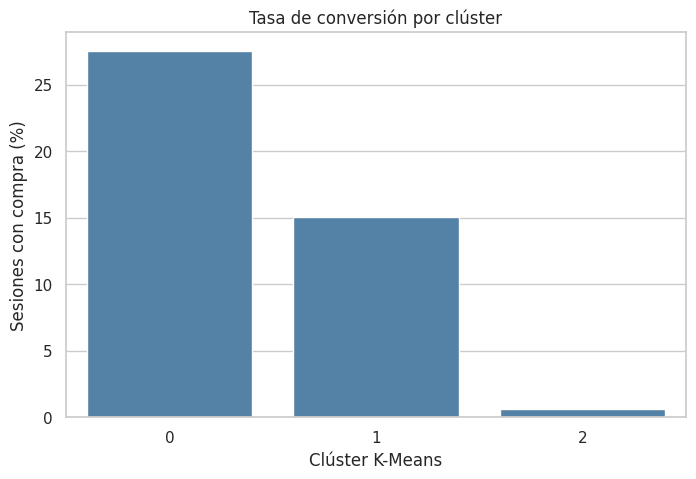

In [14]:
# Comparar el porcentaje de compras entre clústeres
conversion_clusters = df_km.groupby("Cluster")["Revenue"].agg(
    Sesiones="count",
    Compras="sum",
    Tasa_Conversion="mean"
)

conversion_clusters["Tasa_Conversion"] *= 100

display(conversion_clusters.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=conversion_clusters.index,
    y=conversion_clusters["Tasa_Conversion"],
    color="steelblue"
)

plt.title("Tasa de conversión por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Sesiones con compra (%)")
plt.show()

### Relación de los clústeres con las compras

Al comparar los grupos con `Revenue`, encontramos diferencias en sus tasas de conversión:

- **Clúster 0:** 443 compras de 1,607 sesiones, con una conversión de **27.57 %**. Es el grupo con mayor porcentaje de sesiones que terminaron en compra.
- **Clúster 1:** 1,459 compras de 9,679 sesiones, con una conversión de **15.07 %**. Aunque su porcentaje es menor, concentra la mayor cantidad de compras porque contiene muchas más sesiones.
- **Clúster 2:** solamente 6 compras de 919 sesiones, con una conversión de **0.65 %**. Es el grupo con menor porcentaje de sesiones que terminaron en compra y presenta las mayores tasas de rebote y salida.


---


En los grupos analizados, las sesiones con mayor actividad de navegación presentan una proporción más alta de compras. En cambio, las sesiones breves tienen una conversión mucho menor.

Esto muestra una relación entre el comportamiento de navegación y las compras

La variable `Revenue` solamente se utilizó para analizar los grupos después de entrenar K-Means.

## Conclusiones del modelo K-Means

En este proyecto utilizamos K-Means para agrupar 12,205 sesiones de navegación a partir de ocho características numéricas.

Primero estandarizamos las variables con `StandardScaler` y después comparamos diferentes valores de K mediante el método del codo y el coeficiente de silueta. Elegimos K = 3 porque obtuvo el coeficiente de silueta más alto (0.5395) entre los valores evaluados.

Al analizar los centroides y las gráficas encontramos tres grupos: navegación intensiva, navegación moderada y navegación breve con altas tasas de salida.

Lo más interesante fue que estos grupos también presentaron diferencias en las compras. El clúster 0 obtuvo la mayor tasa de conversión (27.57 %), mientras que el clúster 2 registró apenas 0.65 %.

Esto nos permitió identificar un segmento con mayor actividad y conversión, y otro con baja interacción que podría ser importante analizar para mejorar la experiencia de navegación.

**Limitaciones**

- Los valores extremos pueden influir en los centroides calculados por K-Means.
- `BounceRates` y `ExitRates` están muy correlacionadas, por lo que podrían dar más peso a comportamientos similares.
- La silueta se calculó utilizando una muestra de 3,000 sesiones.
- Los resultados muestran asociaciones entre la navegación y las compras, pero no relaciones de causa y efecto.

Como mejora, sería conveniente comparar el modelo con una selección de siete características y comprobar si eliminar una de las tasas correlacionadas modifica la calidad o la interpretación de los grupos.